<a href="https://colab.research.google.com/github/tousif47/Geostormcaster/blob/main/03_model_b_t24h.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Model B: t+24h storm forecast (G1+, with flare features)

Task: detect geomagnetic storms (Kp &gt;= 5, NOAA G1 threshold) in the
3-hour block 24 hours ahead.

- Formulation: binary (storm vs. non-storm), sigmoid output, threshold
  swept on validation
- Features: Kp 27-day recurrence lags, F10.7, sunspot number, 24h solar
  wind context, and GOES X-ray flare activity (counts and irradiance over
  trailing 24h / 7d windows)
- Physics: at 24h lead, in-situ solar wind is uninformative (already
  passed Earth); the predictive signal must come from the Sun — long-term
  activity indices (F10.7, sunspot), the ~27-day rotation recurrence of
  coronal holes, and impulsive flare events
- Data prep, training, and evaluation in this notebook (self-contained
  from omni_clean.csv + flares.csv; does not use Model A's windows)
- Flare coverage starts 1995, so the usable training span is 1995-2010;
  validation and test splits are unchanged

In [1]:
import numpy as np
import json
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, f1_score

tf.keras.utils.set_random_seed(42)

OUT_DIR = '/content/drive/MyDrive/temp'
CSV     = f'{OUT_DIR}/omni_clean.csv'
FLARES  = f'{OUT_DIR}/flares.csv'

## Features and labels

Label: Kp of the 3-hour block 24h ahead (exact block-boundary alignment,
same convention as Model A, shifted by 24h — at +24h the block phase is
identical, so this is a pure 24h shift of the next-block label).

In [2]:
df = pd.read_csv(CSV, parse_dates=['timestamp']).set_index('timestamp').sort_index()
df['kp'] = df['kp'].clip(upper=9)

# --- next-block Kp, then shift 24h for the label ---
kp = df['kp'].values
h = df.index.hour.values
next_off = (3 - (h % 3)) % 3
next_off[next_off == 0] = 3
label_idx = np.arange(len(df)) + next_off
kp_next = np.full(len(df), np.nan)
ok = label_idx < len(df)
kp_next[ok] = kp[label_idx[ok]]

# --- base feature table ---
d = pd.DataFrame(index=df.index)
for lag in [648, 624, 672, 600, 696]:          # Kp at t-27d, +/-1d, +/-2d
    d[f'kp_lag{lag}'] = df['kp'].shift(lag)
d['f107_now'] = df['f107'].ffill()
d['f107_27d'] = df['f107'].shift(648).ffill()
d['ss_now']   = df['sunspot'].ffill()
d['speed_24h'] = df['speed'].rolling(24).mean()
d['bz_24h']    = df['bz_gsm'].rolling(24).mean()

# --- flare features (join on hourly UTC index) ---
fl = pd.read_csv(FLARES, parse_dates=['Unnamed: 0']).set_index('Unnamed: 0')
fl.index.name = 'timestamp'
d = d.join(fl, how='left')

d['label'] = pd.Series(kp_next, index=df.index).shift(-24)

B_FEATS = ['kp_lag648','kp_lag624','kp_lag672','kp_lag600','kp_lag696',
           'f107_now','f107_27d','ss_now','speed_24h','bz_24h',
           'n_24h','n_7d','flux_24h','flux_7d','max_24h','max_7d']
db = d[B_FEATS + ['label']].dropna()

X_b = db[B_FEATS].values.astype(np.float32)
y_b = (db['label'].values >= 5).astype(np.float32)   # storm = G1+ (Kp >= 5)
t_b = db.index
print(f"rows: {len(X_b)}  storm share: {(y_b == 1).mean():.3f}")
print(f"span: {t_b[0]} -> {t_b[-1]}")

rows: 271797  storm share: 0.027
span: 1995-01-08 00:00:00 -> 2026-09-30 01:00:00


## Splits and normalization

Same time-ordered convention as Model A: train <=2010, val 2011-2018,
test 2019-present (train data now starts 1995 due to flare coverage).
Normalization uses train statistics only.

In [3]:
tr = t_b <  '2011-01-01'
va = (t_b >= '2011-01-01') & (t_b < '2019-01-01')
te = t_b >= '2019-01-01'

mu, sd = X_b[tr].mean(axis=0), X_b[tr].std(axis=0)
sd = np.where(sd < 1e-6, 1.0, sd)

def sc(x):
    return (x - mu) / sd

XB = dict(Xtr=sc(X_b[tr]), Xva=sc(X_b[va]), Xte=sc(X_b[te]),
          ytr=y_b[tr], yva=y_b[va], yte=y_b[te],
          ttr=t_b[tr], tva=t_b[va], tte=t_b[te])

for part in ['tr', 'va', 'te']:
    print(f"{part:3s}: n={len(XB['y' + part]):6d}  "
          f"storm={XB['y' + part].mean():.3f}")

np.savez_compressed(f'{OUT_DIR}/windows_b.npz', **XB)
with open(f'{OUT_DIR}/windows_b_norm.json', 'w') as f:
    json.dump({'mean': mu.tolist(), 'std': sd.tolist(), 'features': B_FEATS}, f, indent=1)

tr : n=137876  storm=0.033
va : n= 69975  storm=0.021
te : n= 63946  storm=0.022


## Baselines (validation)

Climatology: always non-storm (the accuracy trap, with real numbers).
Persistence: predict the current block's class ("24h ahead = same as now").
At 24h lead persistence is much weaker than at 3h — storms rarely persist
eight consecutive blocks — so the skill bar is far lower here than in
Model A.

In [4]:
df_kp = df['kp']

def eval_bin(y_true, y_pred, name):
    print(f'--- {name} ---')
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print(classification_report(y_true, y_pred,
          target_names=['non-storm', 'storm'], digits=3, zero_division=0))
    return f1_score(y_true, y_pred)

f1_climo = eval_bin(XB['yva'], np.zeros_like(XB['yva']), 'Climatology (always non-storm)')

cur_kp = df_kp.reindex(XB['tva']).clip(upper=9).values
f1_persist = eval_bin(XB['yva'], (cur_kp >= 5).astype(int), 'Persistence (24h)')

--- Climatology (always non-storm) ---
[[68483     0]
 [ 1492     0]]
              precision    recall  f1-score   support

   non-storm      0.979     1.000     0.989     68483
       storm      0.000     0.000     0.000      1492

    accuracy                          0.979     69975
   macro avg      0.489     0.500     0.495     69975
weighted avg      0.958     0.979     0.968     69975

--- Persistence (24h) ---
[[67091  1392]
 [ 1387   105]]
              precision    recall  f1-score   support

   non-storm      0.980     0.980     0.980     68483
       storm      0.070     0.070     0.070      1492

    accuracy                          0.960     69975
   macro avg      0.525     0.525     0.525     69975
weighted avg      0.960     0.960     0.960     69975



## Model and training

Tabular features, so a compact MLP is the natural architecture. Binary
sigmoid head, class weighting, early stopping — same recipe family as
Model A. Storm class gets 16x weight: the t+24h signal is faint and the
8x used for Model A left the model unable to fire on storms at all.

Epoch 1/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8090 - loss: 0.8575 - val_accuracy: 0.8784 - val_loss: 0.4233
Epoch 2/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8330 - loss: 0.8125 - val_accuracy: 0.8733 - val_loss: 0.4159
Epoch 3/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8363 - loss: 0.7959 - val_accuracy: 0.8718 - val_loss: 0.4049
Epoch 4/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8393 - loss: 0.7854 - val_accuracy: 0.8788 - val_loss: 0.3882
Epoch 5/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8431 - loss: 0.7775 - val_accuracy: 0.8770 - val_loss: 0.3857
Epoch 6/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8437 - loss: 0.7681 - val_accuracy: 0.8698 - val_loss: 0.3915
Epoch 7/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8474 - loss: 0.7605 - val_accuracy: 0.8719 - val_loss: 0.3810
Epoch 8/40
270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8499 - loss: 0.7561 - val_accuracy: 0

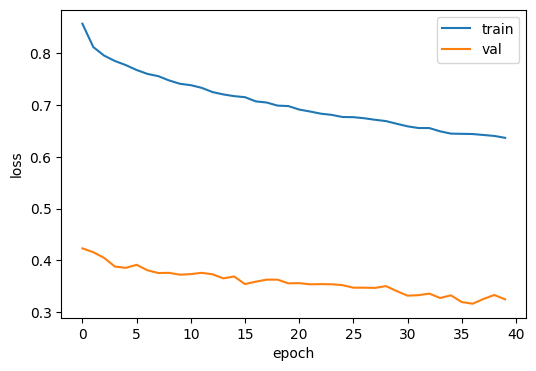

In [5]:
def make_mlp_b():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(16,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')])

m_b = make_mlp_b()
m_b.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
hist_b = m_b.fit(XB['Xtr'], XB['ytr'],
                 validation_data=(XB['Xva'], XB['yva']),
                 epochs=40, batch_size=512, class_weight={0: 1.0, 1: 16.0},
                 callbacks=[tf.keras.callbacks.EarlyStopping(
                     patience=6, restore_best_weights=True)],
                 verbose=1)
m_b.save(f'{OUT_DIR}/model_b_mlp.keras')

plt.figure(figsize=(6, 4))
plt.plot(hist_b.history['loss'], label='train')
plt.plot(hist_b.history['val_loss'], label='val')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.show()

## Threshold sweep (validation)

Predict storm when P(storm) > tau, swept on validation. tau becomes a
fixed constant of the deployed model.

MLP-B: best tau=0.57  val storm F1=0.078


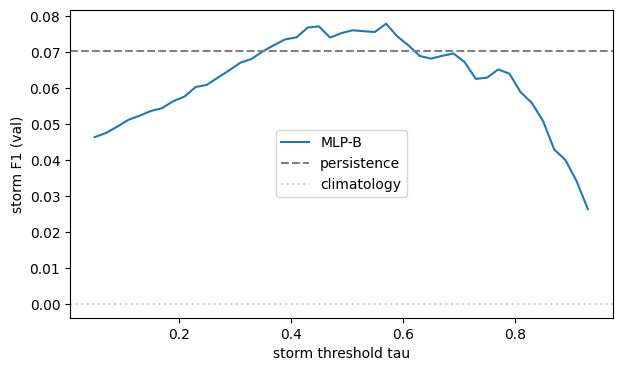

In [6]:
p_va = m_b.predict(XB['Xva'], verbose=0).squeeze()
taus = np.arange(0.05, 0.95, 0.02)
f1s = [f1_score(XB['yva'], (p_va > t).astype(int)) for t in taus]
best = int(np.argmax(f1s))
best_tau = float(taus[best])
print(f'MLP-B: best tau={best_tau:.2f}  val storm F1={f1s[best]:.3f}')

plt.figure(figsize=(7, 4))
plt.plot(taus, f1s, label='MLP-B')
plt.axhline(f1_persist, color='gray', linestyle='--', label='persistence')
plt.axhline(f1_climo, color='lightgray', linestyle=':', label='climatology')
plt.xlabel('storm threshold tau'); plt.ylabel('storm F1 (val)')
plt.legend(); plt.show()

## Test set, once

Same protocol as Model A: model and tau chosen on validation are evaluated
a single time on 2019+ data, alongside persistence on the identical split.
Results go to model_b_results.json.

In [7]:
p_te = m_b.predict(XB['Xte'], verbose=0).squeeze()
pred_te = (p_te > best_tau).astype(int)
f1_test = eval_bin(XB['yte'], pred_te, f'MLP-B (tau={best_tau:.2f}) on TEST')

cur_kp_te = df_kp.reindex(XB['tte']).clip(upper=9).values
f1_persist_te = eval_bin(XB['yte'], (cur_kp_te >= 5).astype(int),
                         'Persistence (24h) on TEST')

print('\n===== FINAL COMPARISON (test split) =====')
print(f'MLP-B (tau={best_tau:.2f})  storm F1 = {f1_test:.3f}')
print(f'Persistence (24h)         storm F1 = {f1_persist_te:.3f}')

summary = {
    'task': 'model_b_t24h_storm_binary_g1',
    'storm_definition': 'Kp >= 5 (G1+)',
    'features': B_FEATS,
    'best_tau': best_tau,
    'val_storm_f1': float(f1s[best]),
    'val_storm_f1_baselines': {'climatology': float(f1_climo),
                               'persistence': float(f1_persist)},
    'test_storm_f1': float(f1_test),
    'test_storm_f1_persistence': float(f1_persist_te),
    'test_report': classification_report(XB['yte'], pred_te,
                      target_names=['non-storm', 'storm'], output_dict=True),
}
with open(f'{OUT_DIR}/model_b_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('saved model_b_results.json')

--- MLP-B (tau=0.57) on TEST ---
[[58631  3903]
 [ 1228   184]]
              precision    recall  f1-score   support

   non-storm      0.979     0.938     0.958     62534
       storm      0.045     0.130     0.067      1412

    accuracy                          0.920     63946
   macro avg      0.512     0.534     0.512     63946
weighted avg      0.959     0.920     0.938     63946

--- Persistence (24h) on TEST ---
[[61247  1287]
 [ 1250   162]]
              precision    recall  f1-score   support

   non-storm      0.980     0.979     0.980     62534
       storm      0.112     0.115     0.113      1412

    accuracy                          0.960     63946
   macro avg      0.546     0.547     0.546     63946
weighted avg      0.961     0.960     0.961     63946


===== FINAL COMPARISON (test split) =====
MLP-B (tau=0.57)  storm F1 = 0.067
Persistence (24h)         storm F1 = 0.113
saved model_b_results.json


In [8]:
# diagnostic: which features carry any t+24h signal at all?
corrs = {}
for i, name in enumerate(B_FEATS):
    corrs[name] = np.corrcoef(XB['Xtr'][:, i], XB['ytr'])[0, 1]
for name, c in sorted(corrs.items(), key=lambda kv: -abs(kv[1])):
    print(f'{name:12s} r = {c:+.4f}')

n_7d         r = +0.1012
kp_lag600    r = +0.0981
max_24h      r = +0.0980
kp_lag624    r = +0.0970
flux_24h     r = +0.0959
f107_now     r = +0.0949
ss_now       r = +0.0936
max_7d       r = +0.0862
flux_7d      r = +0.0838
n_24h        r = +0.0766
f107_27d     r = +0.0729
kp_lag648    r = +0.0629
bz_24h       r = -0.0505
kp_lag672    r = +0.0430
speed_24h    r = +0.0393
kp_lag696    r = +0.0315
